# NadiKampus — Topic Detection (BERTopic)

Notebook ini **hanya untuk topic detection** (tanpa klasifikasi dimensi / fine-tuning IndoBERT), jadi jauh lebih ringan.

**Pipeline:** sentence embedding Indonesia → UMAP → HDBSCAN → c-TF-IDF (+ MMR) → **BERTopic**

**Data:** `nadikampus_corpus_model.parquet` (sudah difilter: valid, tanpa duplikat & jawaban kosong). `nadikampus_corpus_all.parquet` hanya dipakai untuk ringkasan pembersihan.
Kolom yang dipakai: `text_clean` (untuk embedding), `text_tokens` (tanpa stopword, untuk kata representasi topik), `timestamp`, `source`, `doc_type`.

**Jumlah topik:** model tetap menemukan topik halus (puluhan) lalu **digabung menjadi `NR_TOPICS` topik besar** (default 6) supaya cocok untuk dashboard kemahasiswaan. Topik halus tetap disimpan di kolom `topic_fine`.

**Cara pakai:** jalankan sel dari atas ke bawah. Embedding di-*cache* ke `outputs_teks/`, jadi run ulang jauh lebih cepat.

## 0. Setup
Install sekali di terminal (venv Python 3.10–3.12), lalu jalankan sel cek GPU:

```powershell
pip install torch --index-url https://download.pytorch.org/whl/cu124
pip install pandas pyarrow numpy scikit-learn matplotlib plotly nbformat ipykernel
pip install sentence-transformers bertopic umap-learn hdbscan gensim
```

In [1]:
import sys, torch
print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))

Python : 3.11.9
PyTorch: 2.14.0+cu126 | CUDA: True
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Konfigurasi

In [2]:
import os, re, json, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# ---------------- path ----------------
# folder dicari berurutan; file dicari dengan pola *corpus_model.parquet
DATA_DIRS = [Path("data"), Path("dataoutputprocess"), Path(".")]
OUT_DIR = Path("outputs_teks");  OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

# ---------------- model embedding ----------------
EMB_MODEL    = "firqaaa/indo-sentence-bert-base"
EMB_FALLBACK = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MAX_LEN = 128

# ---------------- topic detection ----------------
MIN_TOKENS_TOPIC  = 3     # dokumen < 3 token tidak ikut membentuk topik (hanya di-assign)
MIN_CLUSTER_SIZE  = 25    # naik -> topik lebih sedikit & umum
OUTLIER_THRESHOLD = 0.35  # similarity minimal untuk memindahkan outlier / dokumen pendek ke topik terdekat
RUN_SWEEP = False         # True -> bandingkan beberapa min_cluster_size
NR_TOPICS = 6             # jumlah topik BESAR untuk dashboard (disarankan 4-6). None -> tanpa penggabungan (topik halus saja)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

def find_file(pattern):
    for d in DATA_DIRS:
        hits = sorted(d.glob(pattern)) if d.exists() else []
        if hits:
            return hits[0]
    raise FileNotFoundError(f"Tidak ada file '{pattern}' di {[str(d.resolve()) for d in DATA_DIRS]}")

device: cuda


## 2. Load data & eksplorasi singkat

In [3]:
df = pd.read_parquet(find_file("*corpus_model.parquet")).reset_index(drop=True)
try:
    df_all = pd.read_parquet(find_file("*corpus_all.parquet"))
except FileNotFoundError:
    df_all = None

for c in ["source", "doc_type"]:
    df[c] = df[c].astype(str)
df["timestamp"] = pd.to_datetime(df["timestamp"])
if "n_tokens" not in df.columns:
    df["n_tokens"] = df["text_tokens"].fillna("").str.split().str.len()
if "n_words" not in df.columns:
    df["n_words"] = df["text_clean"].fillna("").str.split().str.len()
df["text_clean"]  = df["text_clean"].fillna("")
df["text_tokens"] = df["text_tokens"].fillna("")

if df_all is not None:
    print(f"corpus_all  : {len(df_all):,} baris")
print(f"corpus_model: {len(df):,} baris")
print(f"Rentang waktu: {df.timestamp.min()}  ->  {df.timestamp.max()}")
display(df.groupby(["source", "doc_type"]).size().rename("n").to_frame())

corpus_all  : 5,433 baris
corpus_model: 5,342 baris
Rentang waktu: 2026-08-01 03:13:16  ->  2026-10-20 23:20:10


,,n
source,doc_type,
gform,survey_answer,553
telegram,post,4789


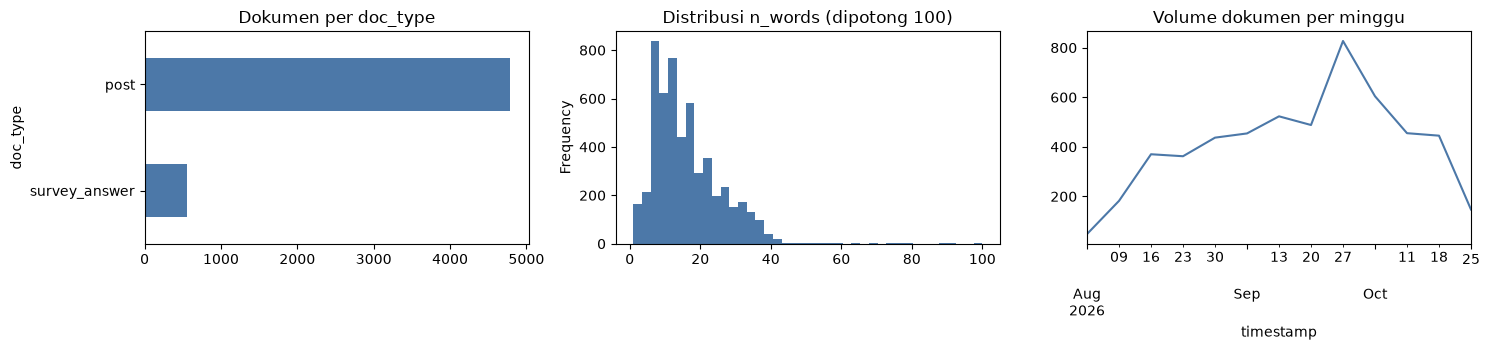

Dokumen dengan n_tokens < MIN_TOKENS_TOPIC: 211


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
df.groupby("doc_type").size().sort_values().plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Dokumen per doc_type")
df.n_words.clip(upper=100).plot.hist(bins=40, ax=ax[1], color="#4C78A8"); ax[1].set_title("Distribusi n_words (dipotong 100)")
df.set_index("timestamp").resample("W").size().plot(ax=ax[2], color="#4C78A8"); ax[2].set_title("Volume dokumen per minggu")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_overview.png", dpi=150); plt.show()
print("Dokumen dengan n_tokens < MIN_TOKENS_TOPIC:", (df.n_tokens < MIN_TOKENS_TOPIC).sum())

## 3. Sentence embedding
Dihitung sekali dari `text_clean` (teks natural, tidak di-stem) lalu di-cache.

In [5]:
from sentence_transformers import SentenceTransformer

def load_st(name):
    m = SentenceTransformer(name, device=device)
    m.max_seq_length = MAX_LEN
    return m

try:
    st_model, EMB_NAME_USED = load_st(EMB_MODEL), EMB_MODEL
except Exception as e:
    print(f"[!] Gagal memuat {EMB_MODEL}: {type(e).__name__}. Pakai fallback {EMB_FALLBACK}")
    st_model, EMB_NAME_USED = load_st(EMB_FALLBACK), EMB_FALLBACK

emb_path = OUT_DIR / f"emb_{EMB_NAME_USED.replace('/', '_')}_{len(df)}.npy"
if emb_path.exists():
    emb = np.load(emb_path); print("Embedding dimuat dari cache:", emb.shape)
else:
    t0 = time.time()
    emb = st_model.encode(df.text_clean.tolist(), batch_size=64, show_progress_bar=True,
                          normalize_embeddings=True, convert_to_numpy=True)
    np.save(emb_path, emb); print(f"Embedding {emb.shape} selesai dalam {time.time()-t0:.0f} dtk")
assert len(emb) == len(df)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embedding dimuat dari cache: (5342, 768)


## 4. BERTopic
- Embedding dari `text_clean`; **kata representasi topik** dari `text_tokens` (tanpa stopword) agar label bersih.
- Disimpan dua versi: `topic_raw` (apa adanya, outlier = -1) dan `topic` (outlier dipindah ke topik terdekat bila similarity ≥ `OUTLIER_THRESHOLD`).
- **Dua level topik:** `topic_fine` = topik halus hasil HDBSCAN (setelah outlier dipindah); `topic` = topik besar hasil penggabungan ke `NR_TOPICS` (untuk dashboard).
- Dokumen sangat pendek (< `MIN_TOKENS_TOPIC` token) tidak ikut fit; mereka di-assign ke **centroid topik terdekat** (cosine similarity pada embedding), bukan lewat `transform` HDBSCAN yang cenderung membuang semuanya jadi outlier.

In [6]:
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

# kata khas menfess yang tidak informatif untuk label topik (tambah sesuai hasil inspeksi)
EXTRA_STOPWORDS = ["sender", "nder", "rek", "ya", "yah", "dong", "sih", "nih", "deh", "kok", "lho", "loh",
                   "aja", "gak", "banget", "tolong", "makasih", "terima", "kasih", "halo", "min", "admin"]

topic_mask = (df.n_tokens >= MIN_TOKENS_TOPIC).to_numpy()
docs_fit = df.loc[topic_mask, "text_tokens"].tolist()
emb_fit  = emb[topic_mask]
print(f"Dokumen untuk fit topik: {topic_mask.sum():,} | hanya di-assign: {(~topic_mask).sum():,}")

def make_topic_model(min_cluster_size=MIN_CLUSTER_SIZE, verbose=True):
    return BERTopic(
        embedding_model=None,   # embedding diberikan manual
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=min_cluster_size, min_samples=5, metric="euclidean",
                              cluster_selection_method="eom", prediction_data=True),
        vectorizer_model=CountVectorizer(ngram_range=(1, 2), min_df=3, stop_words=EXTRA_STOPWORDS),
        representation_model=MaximalMarginalRelevance(diversity=0.4),
        top_n_words=10, calculate_probabilities=False, verbose=verbose,
    )

Dokumen untuk fit topik: 5,131 | hanya di-assign: 211


In [7]:
topic_model = make_topic_model()
topics, probs = topic_model.fit_transform(docs_fit, embeddings=emb_fit)
topics = np.array(topics)
n_topics_raw = len(set(topics)) - (1 if -1 in topics else 0)
print(f"\nTopik halus ditemukan: {n_topics_raw} | outlier mentah: {(topics == -1).mean():.1%}")

# 1) pindahkan outlier ke topik terdekat (berdasarkan embedding)
topics_red = topic_model.reduce_outliers(docs_fit, topics.tolist(), strategy="embeddings",
                                         embeddings=emb_fit, threshold=OUTLIER_THRESHOLD)
topic_model.update_topics(docs_fit, topics=topics_red,
                          vectorizer_model=topic_model.vectorizer_model,
                          representation_model=MaximalMarginalRelevance(diversity=0.4))
topics_fine = np.array(topics_red)
print(f"Outlier setelah reduce_outliers: {(topics_fine == -1).mean():.1%}")

# simpan ringkasan topik halus sebelum digabung
info_fine = topic_model.get_topic_info().copy()
info_fine["kata_kunci"] = info_fine.Topic.map(
    lambda t: ", ".join(w for w, _ in topic_model.get_topic(t)[:8]) if t != -1 else "-")

# 2) gabungkan topik halus -> NR_TOPICS topik besar (hierarchical merge berdasarkan c-TF-IDF)
if NR_TOPICS and n_topics_raw > NR_TOPICS:
    topic_model.reduce_topics(docs_fit, nr_topics=NR_TOPICS)
    topics_red = np.array(topic_model.topics_)
else:
    topics_red = topics_fine.copy()
n_big = len(set(topics_red) - {-1})
print(f"Topik besar untuk dashboard: {n_big} (target NR_TOPICS={NR_TOPICS})")
if NR_TOPICS and n_big != NR_TOPICS:
    print("   [i] Jumlah akhir bisa berbeda 1 dari target karena penanganan outlier -n_topic; ubah NR_TOPICS bila perlu.")

# --- centroid tiap topik (dari embedding dokumen anggota) ---
def build_centroids(labels):
    ids = sorted(t for t in set(labels) if t != -1)
    cen = np.vstack([emb_fit[labels == t].mean(0) for t in ids])
    cen /= np.linalg.norm(cen, axis=1, keepdims=True)
    return ids, cen

topic_ids, centroids = build_centroids(topics_red)             # level dashboard
topic_ids_fine, centroids_fine = build_centroids(topics_fine)  # level halus

def assign_by_centroid(e, thr=OUTLIER_THRESHOLD, fine=False):
    """Assign embedding ke topik terdekat; -1 bila similarity < thr."""
    ids, cen = (topic_ids_fine, centroids_fine) if fine else (topic_ids, centroids)
    sims = e @ cen.T
    best, mx = sims.argmax(1), sims.max(1)
    return np.where(mx >= thr, np.array(ids)[best], -1), mx

# --- tulis hasil ke dataframe ---
df["topic_raw"] = -1      # HDBSCAN apa adanya (halus, outlier = -1)
df["topic_fine"] = -1     # topik halus setelah outlier dipindah
df["topic"] = -1          # topik BESAR untuk dashboard
df["topic_score"] = np.nan     # dokumen fit: membership prob HDBSCAN | dokumen pendek: cosine ke centroid
df.loc[topic_mask, "topic_raw"]   = topics
df.loc[topic_mask, "topic_fine"]  = topics_fine
df.loc[topic_mask, "topic"]       = topics_red
df.loc[topic_mask, "topic_score"] = np.asarray(probs, dtype=float)

short = ~topic_mask
if short.any():
    t_short, s_short = assign_by_centroid(emb[short])
    t_short_f, _ = assign_by_centroid(emb[short], fine=True)
    df.loc[short, "topic_raw"]  = t_short_f
    df.loc[short, "topic_fine"] = t_short_f
    df.loc[short, "topic"] = t_short
    df.loc[short, "topic_score"] = s_short

info = topic_model.get_topic_info()
print(f"Outlier akhir di seluruh korpus: {(df.topic == -1).mean():.1%}")
display(info[["Topic", "Count", "Name"]])

# proporsi tiap topik besar (inilah yang ditampilkan di "Topik dominan")
share = (df[df.topic != -1].topic.value_counts(normalize=True).mul(100).round(1)
           .rename("persen").rename_axis("Topic").reset_index())
display(share)

2026-10-30 15:30:00,819 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-30 15:30:35,567 - BERTopic - Dimensionality - Completed ✓
2026-10-30 15:30:35,569 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-30 15:30:35,715 - BERTopic - Cluster - Completed ✓
2026-10-30 15:30:35,722 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-30 15:30:35,842 - BERTopic - Representation - Completed ✓
2026-10-30 15:30:36,025 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-10-30 15:30:36,138 - BERTopic - Topic reduction - Reducing number of topics
2026-10-30 15:30:36,155 - BERTopic - Representation - Fine-tuning topics using representati


Topik halus ditemukan: 38 | outlier mentah: 20.4%
Outlier setelah reduce_outliers: 1.1%


2026-10-30 15:30:36,243 - BERTopic - Representation - Completed ✓
2026-10-30 15:30:36,246 - BERTopic - Topic reduction - Reduced number of topics from 39 to 6


Topik besar untuk dashboard: 5 (target NR_TOPICS=6)
   [i] Jumlah akhir bisa berbeda 1 dari target karena penanganan outlier -n_topic; ubah NR_TOPICS bila perlu.
Outlier akhir di seluruh korpus: 2.9%


,Topic,Count,Name
0,-1,57,-1_indonesia_ibu_pergi_tetap
1,0,3559,0_info_kampus_tanya_tempat
2,1,756,1_iki_wes_yo_punya
3,2,518,2_orang_teman_tidur_salah
4,3,163,3_teman_orangtua_kuliah_keluarga
5,4,78,4_lampu_ac_panas_d4


,Topic,persen
0,0,69.1
1,1,14.9
2,2,10.1
3,3,4.2
4,4,1.7


### Inspeksi topik
Baca kata kunci **dan contoh teks asli**, lalu beri nama manusiawi lewat `TOPIC_LABELS` di sel berikutnya.

In [8]:
def show_topic_examples(topic_ids_to_show=None, n_topics=15, n_examples=4):
    ids = topic_ids_to_show or [t for t in info.Topic.tolist() if t != -1][:n_topics]
    for t in ids:
        words = ", ".join(w for w, _ in topic_model.get_topic(t)[:8])
        cnt = int(info.loc[info.Topic == t, "Count"].iloc[0])
        print(f"\n=== Topik {t}  (n={cnt})  :: {words}")
        ex = df[(df.topic == t) & df.topic_score.notna()].nlargest(n_examples, "topic_score")
        for txt in ex.text_clean:
            print("   •", txt[:160].replace("\n", " "))

show_topic_examples()                  # semua topik besar (hanya beberapa)


=== Topik 0  (n=3559)  :: info, kampus, tanya, tempat, tahu, teman, kos, maba
   • Sender punya bisnis yang Alhamdulillah lolos pendanaan PMW nihh 🥹✨ Lagi cari 1 anggota angkatan 2025 buat posisi CCO, terutama yang suka desain/konten. Tertarik
   • Ada yang jual sepatu futsal gak?
   • guys sender maba, mau tanya semester 1 ga ikut ukm dulu boleh ngga ya (soalnya masih bingung mana pendaftarannya udah mau tutup semua lagi)😃😃
   • Normal ga si dah tahun kedua kuliah tbtb hilang arah jir 😔

=== Topik 1  (n=756)  :: iki, wes, yo, punya, anak, opo, sek, ta
   • So this is how it feels to be a line without a hook
   • plis lah parkirane pedahku beset kabeh cok
   • Menang 5-2 fans sebelah ga onk seng koar koar ta? 😎
   • kiw mbaa d4 it'b24 "." udah ada yang punya belum mba?

=== Topik 2  (n=518)  :: orang, teman, tidur, salah, lgbt, merasa, cowok, jangan
   • heh tolong ya kalau disapa itu balik nyapa dongg, malu bgt udah nyapa tp ga dibales akk (kek ga saling kenal aja) 💔💔
   • Ini kalo r

In [9]:
# Isi setelah membaca contoh di atas. Nama harus sesuai id topik BESAR yang tercetak di sel sebelumnya,
# mis. {0: "Beban tugas & ujian", 1: "Kecemasan karier & magang", 2: "Biaya kuliah & keuangan", ...}
TOPIC_LABELS = {}

name_map = dict(zip(info.Topic, info.Name))
df["topic_label"] = df.topic.map(lambda t: TOPIC_LABELS.get(t, name_map.get(t, str(t))))
print(df.topic_label.value_counts().head(15))

topic_label
0_info_kampus_tanya_tempat          3584
1_iki_wes_yo_punya                   770
2_orang_teman_tidur_salah            524
3_teman_orangtua_kuliah_keluarga     218
-1_indonesia_ibu_pergi_tetap         157
4_lampu_ac_panas_d4                   89
Name: count, dtype: int64


### Visualisasi (disimpan sebagai HTML interaktif di `outputs_teks/figures/`)

In [10]:
def show_and_save(make_fig, fname):
    try:
        fig = make_fig()
        fig.write_html(str(FIG_DIR / fname)); fig.show()
    except Exception as e:
        print(f"[skip {fname}] {type(e).__name__}: {e}")

n_real = len([t for t in info.Topic if t != -1])
show_and_save(lambda: topic_model.visualize_barchart(top_n_topics=min(12, n_real), n_words=8), "topic_barchart.html")
show_and_save(lambda: topic_model.visualize_topics(), "topic_intertopic_map.html")
show_and_save(lambda: topic_model.visualize_hierarchy(), "topic_hierarchy.html")
show_and_save(lambda: topic_model.visualize_heatmap(), "topic_similarity_heatmap.html")

In [11]:
# Tren topik dari waktu ke waktu
ts_fit = df.loc[topic_mask, "timestamp"].tolist()
topics_over_time = topic_model.topics_over_time(docs_fit, ts_fit, nr_bins=10)
show_and_save(lambda: topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=min(8, n_real)),
              "topic_over_time.html")

10it [00:00, 58.20it/s]


### Evaluasi kualitas topik
- **Coherence c_v** (makin tinggi makin koheren) dan **topic diversity** (proporsi kata unik antar topik).
- **Validasi eksternal lemah** (opsional, jika kolom `dimension` ada): kesesuaian topik dengan label dimensi pada jawaban survei (NMI/ARI). Tidak diharapkan tinggi, berguna untuk membandingkan konfigurasi.

In [12]:
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

def topic_quality(tm, docs, topk=10):
    tokenized = [d.split() for d in docs]
    dictionary = Dictionary(tokenized)
    tw = []
    for t in tm.get_topics():
        if t == -1: continue
        words = [w for w, _ in tm.get_topic(t)[:topk]]
        uni = list(dict.fromkeys(x for w in words for x in w.split() if x in dictionary.token2id))  # pecah bigram
        if len(uni) >= 2: tw.append(uni)
    coh = CoherenceModel(topics=tw, texts=tokenized, dictionary=dictionary, coherence="c_v", processes=1).get_coherence()
    flat = [w for ws in tw for w in ws]
    return {"n_topics": len(tw), "coherence_c_v": round(coh, 4), "diversity": round(len(set(flat)) / len(flat), 4)}

print("Kualitas topik:", topic_quality(topic_model, docs_fit))

if "dimension" in df.columns:
    from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
    g = df[(df.source == "gform") & df.dimension.notna() & (df.topic != -1)]
    if len(g):
        print(f"Kesesuaian dengan label dimension (gform, n={len(g)}): "
              f"NMI={normalized_mutual_info_score(g.dimension.astype(str), g.topic):.3f} | "
              f"ARI={adjusted_rand_score(g.dimension.astype(str), g.topic):.3f}")

Kualitas topik: {'n_topics': 5, 'coherence_c_v': np.float64(0.3679), 'diversity': 0.94}
Kesesuaian dengan label dimension (gform, n=462): NMI=0.200 | ARI=0.171


In [13]:
if RUN_SWEEP:
    rows = []
    for mcs in [15, 25, 40, 60]:
        tm = make_topic_model(mcs, verbose=False)
        tp, _ = tm.fit_transform(docs_fit, embeddings=emb_fit)
        q = topic_quality(tm, docs_fit); q.update({"min_cluster_size": mcs, "outlier_%": round((np.array(tp) == -1).mean() * 100, 1)})
        rows.append(q); print(q)
    display(pd.DataFrame(rows).set_index("min_cluster_size"))
else:
    print("RUN_SWEEP=False -> lewati. Set True di sel konfigurasi untuk membandingkan min_cluster_size.")

RUN_SWEEP=False -> lewati. Set True di sel konfigurasi untuk membandingkan min_cluster_size.


## 5. Simpan hasil

In [14]:
# --- model ---
try:
    topic_model.save(str(OUT_DIR / "bertopic_model"), serialization="safetensors",
                     save_ctfidf=True, save_embedding_model=EMB_NAME_USED)
except Exception as e:
    print(f"[skip save model] {type(e).__name__}: {e}")

# --- ringkasan topik + contoh dokumen representatif ---
info = topic_model.get_topic_info()
info["label"] = info.Topic.map(lambda t: TOPIC_LABELS.get(t, ""))
info.to_csv(OUT_DIR / "topic_info.csv", index=False, encoding="utf-8-sig")          # topik besar (dashboard)
info_fine.to_csv(OUT_DIR / "topic_info_fine.csv", index=False, encoding="utf-8-sig") # topik halus (analisis)

# --- ringkasan untuk dashboard: tanpa teks asli, aman diunggah ke GitHub ---
dash = (df[df.topic != -1].groupby(["topic", "topic_label"]).size().rename("n").reset_index())
dash["persen"] = (dash.n / dash.n.sum() * 100).round(1)
dash["kata_kunci"] = dash.topic.map(lambda t: ", ".join(w for w, _ in topic_model.get_topic(t)[:8]))
dash = dash.sort_values("n", ascending=False)
dash.to_csv(OUT_DIR / "dashboard_topics.csv", index=False, encoding="utf-8-sig")
dash.to_json(OUT_DIR / "dashboard_topics.json", orient="records", force_ascii=False, indent=2)
display(dash)

rep = (df[df.topic != -1].sort_values("topic_score", ascending=False)
         .groupby("topic").head(5)[["topic", "topic_label", "source", "doc_type", "topic_score", "text_clean"]]
         .sort_values(["topic", "topic_score"], ascending=[True, False]))
rep.to_csv(OUT_DIR / "topic_representative_docs.csv", index=False, encoding="utf-8-sig")

# --- tren topik bulanan (siap untuk dashboard) ---
trend = (df[df.topic != -1].assign(bulan=lambda d: d.timestamp.dt.to_period("M").astype(str))
           .groupby(["bulan", "topic", "topic_label"]).size().rename("n").reset_index())
trend.to_csv(OUT_DIR / "topic_monthly_trend.csv", index=False, encoding="utf-8-sig")

# --- hasil per dokumen ---
out_cols = [c for c in ["doc_id", "source", "doc_type", "timestamp", "text_clean",
                        "topic_raw", "topic_fine", "topic", "topic_label", "topic_score"] if c in df.columns]
df[out_cols].to_parquet(OUT_DIR / "nadikampus_topics.parquet", index=False)
df[out_cols].to_csv(OUT_DIR / "nadikampus_topics.csv", index=False, encoding="utf-8-sig")
print("Tersimpan di outputs_teks/: bertopic_model, topic_info(.csv|_fine.csv), dashboard_topics.(csv|json), "
      "topic_representative_docs.csv, topic_monthly_trend.csv, nadikampus_topics.(parquet|csv)")
print("[!] topic_representative_docs.csv & nadikampus_topics.* berisi teks asli -> jangan di-push ke GitHub publik.")

,topic,topic_label,n,persen,kata_kunci
0,0,0_info_kampus_tanya_tempat,3584,69.1,"info, kampus, tanya, tempat, tahu, teman, kos, maba"
1,1,1_iki_wes_yo_punya,770,14.9,"iki, wes, yo, punya, anak, opo, sek, ta"
2,2,2_orang_teman_tidur_salah,524,10.1,"orang, teman, tidur, salah, lgbt, merasa, cowok, jangan"
3,3,3_teman_orangtua_kuliah_keluarga,218,4.2,"teman, orangtua, kuliah, keluarga, teman teman, orang, baik, masa depan"
4,4,4_lampu_ac_panas_d4,89,1.7,"lampu, ac, panas, d4, d3, nrp, gedung, listrik"


Tersimpan di outputs_teks/: bertopic_model, topic_info(.csv|_fine.csv), dashboard_topics.(csv|json), topic_representative_docs.csv, topic_monthly_trend.csv, nadikampus_topics.(parquet|csv)
[!] topic_representative_docs.csv & nadikampus_topics.* berisi teks asli -> jangan di-push ke GitHub publik.


## 6. Inferensi untuk teks baru

In [15]:
def analyze(texts, thr=OUTLIER_THRESHOLD):
    """Topik terdekat (by centroid) untuk teks baru. Contoh: analyze(["UKT mahal banget"])"""
    texts = [texts] if isinstance(texts, str) else list(texts)
    e = st_model.encode(texts, normalize_embeddings=True, convert_to_numpy=True)
    t, s = assign_by_centroid(e, thr)
    return pd.DataFrame({
        "text": texts, "topic": t, "similarity": s.round(3),
        "topic_label": [df.loc[df.topic == x, "topic_label"].iloc[0] if x != -1 else "-" for x in t],
        "topic_words": [", ".join(w for w, _ in topic_model.get_topic(x)[:5]) if x != -1 else "-" for x in t]})

analyze(["Ada yang jual laptop second harga murah?",
         "Kantin hari ini buka jam berapa ya",
         "Motor saya hilang di parkiran"])

,text,topic,similarity,topic_label,topic_words
0,Ada yang jual laptop second harga murah?,-1,0.341,-,-
1,Kantin hari ini buka jam berapa ya,0,0.489,0_info_kampus_tanya_tempat,"info, kampus, tanya, tempat, tahu"
2,Motor saya hilang di parkiran,-1,0.297,-,-


## Catatan
- **Jumlah topik di dashboard:** atur `NR_TOPICS` (4-6 disarankan). Topik halus tetap ada di `topic_fine` / `topic_info_fine.csv`. Beri nama topik besar lewat `TOPIC_LABELS`, lalu jalankan ulang sel simpan hasil.
- **Topik halus terlalu banyak/sedikit:** ubah `MIN_CLUSTER_SIZE` (atau `RUN_SWEEP=True`). Topik campur-aduk bahasa Jawa (mis. `iki, wes, yo`) bisa ditangani dengan menambah kata ke `EXTRA_STOPWORDS`.
- **Banyak outlier:** turunkan `OUTLIER_THRESHOLD` (mis. 0.30) atau `MIN_CLUSTER_SIZE`.
- **Dokumen pendek** (< `MIN_TOKENS_TOPIC` token) di-assign lewat centroid; bila ingin diabaikan seluruhnya, filter `n_tokens >= MIN_TOKENS_TOPIC` saat analisis.
- Hasil reproducible (seed 42, UMAP `random_state`) pada mesin yang sama.